## Exercise 


For this exercise, you will be working with the [House Price Dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/code).

Please grab the train.csv file from Kaggle and explore this dataset. You need to perform explroatory data analysis and see if there is any correlation between the variables and analyze the distribution of the dataset. The question is open-ended and basically you're asked to perform ED

1- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 3 of your assignment, you need to submit at least one jupyter notebook file and one pdf file.


2- Push your code and project to github and provide the link to your code here. Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

- Src
- Data
- Docs
- Results

Read this link for further info:  https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510

**Personnal notes**

#### Purpose of the project
- **Training Set (`train.csv`)**: Contains the features of the houses (size, rooms, year built) along with their true target value (`SalePrice`). We use this as our "answer key" so the machine learning model can learn mathematical patterns (e.g., how an extra square foot or better quality affects the price).
- **Test Set (`test.csv`)**: Contains features for new houses, but the `SalePrice` column is completely missing.
- **The Goal**: To Perform an EDA of the given dataset.
- 
#### Purpose of EDA (Exploratory Data Analysis)
EDA is the preliminary diagnostic phase before building any model. Its main purposes are:
- **Understand the Data**: Detect errors, missing values (e.g., houses without a garage), or extreme outliers that could ruin predictions.
- **Find Relationships**: Discover which features matter the most (e.g., how size or overall quality drives the price up or down).
- **Make Decisions**: Help us decide which columns to clean, which ones to drop, and what transformations the model needs to perform better.


In [77]:
# Import galleries
import os
import pandas as pd #library to manipulate data
import matplotlib.pyplot as plt #library for graphics
import seaborn as sns

# 2. Configurar el estilo visual de los gráficos
sns.set_theme(style="whitegrid")

# Read the dataset
# Como nuestro notebook está en 'Src', subimos un nivel ('..') y entramos a 'Data'
ruta_train = os.path.join("..", "Data", "train.csv") 
#os.path.join("..", "Data", "train.csv") we use this to create a path, I said to python jump out of "Scr" and go in to data and search
#read the document .cvs
df_train = pd.read_csv(ruta_train)



## 1. Structure and dimension ##

#### 1.1 Dataframe dimension and preview

In [78]:
df_train.shape

(1460, 81)

In [3]:
df_train.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### 1.2 General information and data types

In [6]:
print("General information and null values")
df_train.info()

General information and null values
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-nul

#### 1.3 Staistical summary and Numerical variables

**Statistical summary**

In [7]:
print("Statistical summary")
df_train.describe().T[["count", "mean", "std", "min", "50%", "max"]].head(10|)

Statistical summary


,count,mean,std,min,50%,max
Id,1460.0,730.500000,421.610009,1.0,730.5,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,50.0,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,69.0,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,9478.5,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,6.0,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.0,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1973.0,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1994.0,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.0,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,383.5,5644.0


**Numerical variables**

In [55]:
numeric_cols = df_train.select_dtypes(include=['float64', 'int64'])
numeric_cols

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,0,61,0,0,0,0,0,2,2008,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,298,0,0,0,0,0,0,5,2007,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,0,42,0,0,0,0,0,9,2008,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,0,35,272,0,0,0,0,2,2006,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,62.0,7917,6,5,1999,2000,0.0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,1457,20,85.0,13175,6,6,1978,1988,119.0,790,...,349,0,0,0,0,0,0,2,2010,210000
1457,1458,70,66.0,9042,7,9,1941,2006,0.0,275,...,0,60,0,0,0,0,2500,5,2010,266500
1458,1459,20,68.0,9717,5,6,1950,1996,0.0,49,...,366,0,112,0,0,0,0,4,2010,142125


## 2. Missing Values Analysis

**2.1 Quantification of Null Data**

In [14]:
#Check for missing values and sort them descending
missing_data = df_train.isnull().sum()

#Python, from my  missing_data, create a variable " missing_data"
# That comes from " missing_data" and the values in there I want the >0 ones
missing_data = missing_data[ missing_data > 0].sort_values(ascending = False)
print ("Columns with missing values:")
print (missing_data.head(10))

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
dtype: int64


**2.2 Percentage of Null Data**

In [58]:
# Calculate percentage of missing values
#Calculates the percentage of missing values in each column
missing_data = (df_train.isnull().sum() / len(df_train)) * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False).head(10)
missing_data

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
dtype: float64

**2.3 Bar plot: Top Features with Missing values**

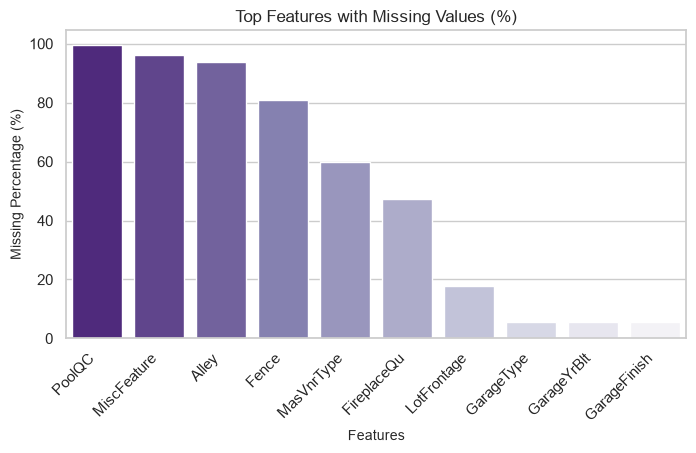

In [38]:
plt.figure(figsize=(8, 4))
sns.barplot(x=missing_data.index, y=missing_data.values, palette='Purples_r', hue=missing_data.index, legend=False)

plt.title('Top Features with Missing Values (%)', fontsize=12)
plt.xlabel('Features', fontsize=10)
plt.ylabel('Missing Percentage (%)', fontsize=10)
plt.xticks(rotation=45, ha='right')

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/missing_values_top.png', bbox_inches='tight')
plt.show()

## 3. Univariate Analysis: Numerical Variables ##

### 3.1 Histogram of KDE Curve for Sale Price and Living Area

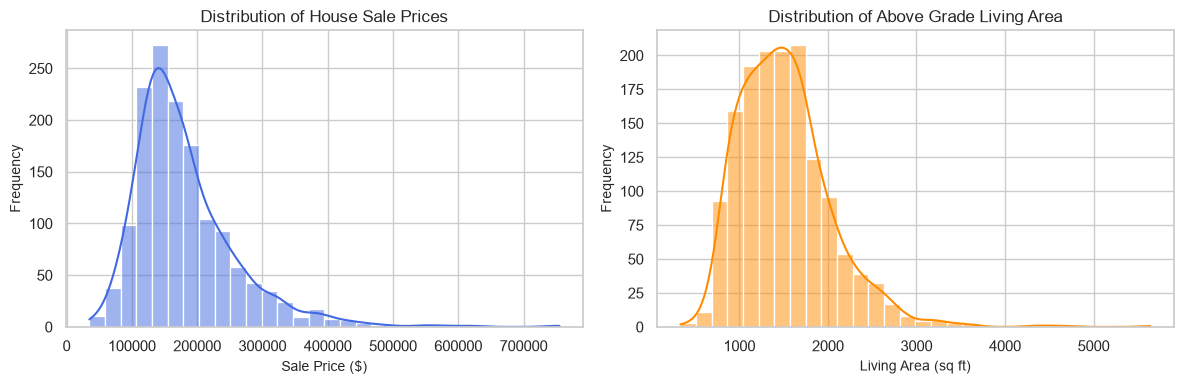

In [26]:
# Two subplots to analyze distributions of SalePrice and GrLivArea

#Subplot ( 1 column, 2 rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Plot histogram and KDE for SalePrice
#From df_train take column ['SalePrice'] #kde= provides the density of probability axes[0][1]= left and right
sns.histplot(df_train['SalePrice'], kde=True, color='royalblue', ax=axes[0], bins=30)
axes[0].set_title('Distribution of House Sale Prices', fontsize=12)
axes[0].set_xlabel('Sale Price ($)', fontsize=10)
axes[0].set_ylabel('Frequency', fontsize=10)


# Plot histogram and KDE for GrLivArea (Above Grade Living Area)
#From df_train take column ['GrLivArea'] #kde= provides the density of probability axes[0][1]= left and right
sns.histplot(df_train['GrLivArea'], kde=True, color='darkorange', ax=axes[1], bins=30)
axes[1].set_title('Distribution of Above Grade Living Area', fontsize=12)
axes[1].set_xlabel('Living Area (sq ft)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)


plt.tight_layout()
plt.savefig('../Results/distributions_univariate.png', bbox_inches='tight')
plt.show()

In [66]:
df_train[['SalePrice',"GrLivArea"] ].describe().T[["count", "mean", "std", "min", "50%", "max", "75%", "25%"]].head(10)

,count,mean,std,min,50%,max,75%,25%
SalePrice,1460.0,180921.195890,79442.502883,34900.0,163000.0,755000.0,214000.00,129975.0
GrLivArea,1460.0,1515.463699,525.480383,334.0,1464.0,5642.0,1776.75,1129.5


### 3.2 Frequency Distribution of Property Qualities

In [80]:
df_train["OverallQual"].describe().T[["count", "mean", "std", "min", "50%", "max", "75%", "25%"]].head(10)

count    1460.000000
mean        6.099315
std         1.382997
min         1.000000
50%         6.000000
max        10.000000
75%         7.000000
25%         5.000000
Name: OverallQual, dtype: float64

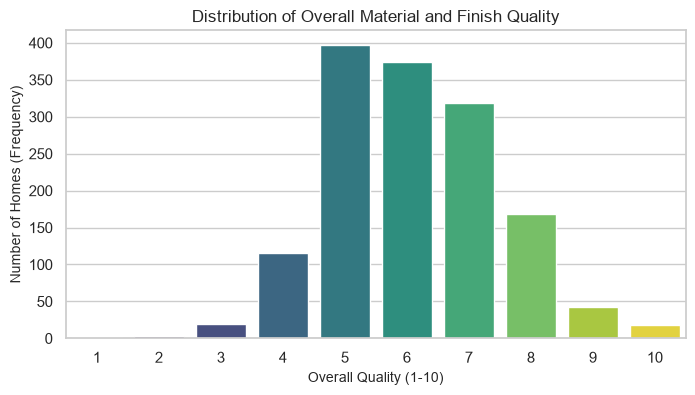

In [28]:
# Count plot for OverallQual to see the frequency distribution of property qualities
#Plot count for continuous variables, counts how many housee belongs to each categorical discrete variable
plt.figure(figsize=(8, 4))
sns.countplot(x='OverallQual', data=df_train, palette='viridis', hue='OverallQual', legend=False)
plt.title('Distribution of Overall Material and Finish Quality', fontsize=12)
plt.xlabel('Overall Quality (1-10)', fontsize=10)
plt.ylabel('Number of Homes (Frequency)', fontsize=10)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/overall_quality_count.png', bbox_inches='tight')
plt.show()

## 4. Bivariate Analysis: Correlation and Numerical Relationships ##

### 4.1 Filtering numerical variables and Correlation Matrix

In [60]:
# To find which variables influence on the prices

#Select only numerical variables to calculate correlations
#Filter numerical variables by columns
numeric_cols = df_train.select_dtypes(include=['float64', 'int64'])

#Create a correlation matrix with the previous numerical variables .corr()
corr_matrix = numeric_cols.corr()
corr_matrix.head(10)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


#### 4.2 Correlation Heatmap with Sale Price

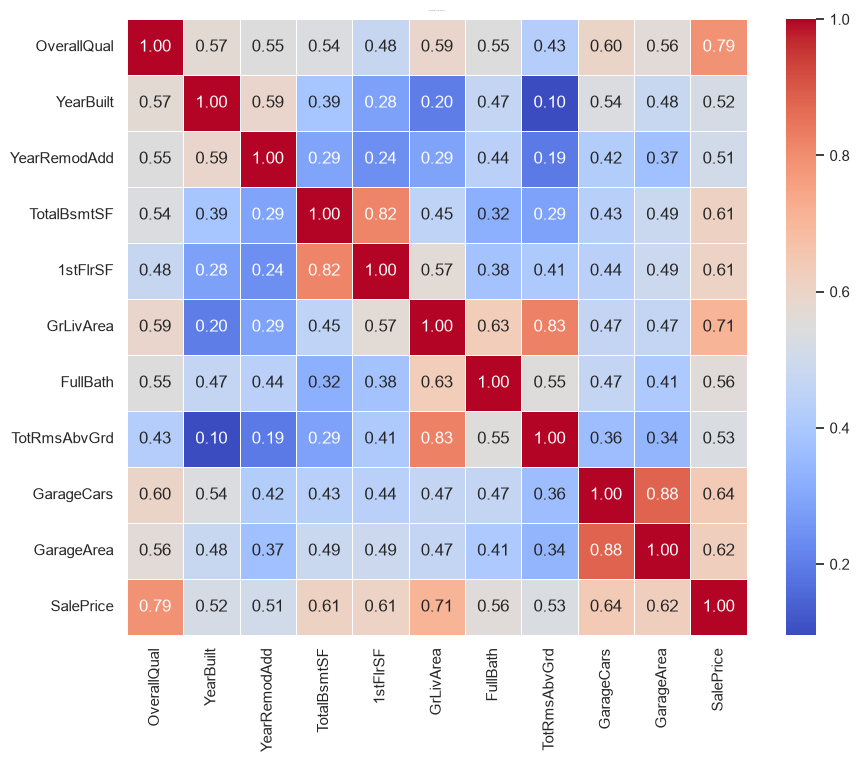

In [11]:
#Plot the top variables most correlated with SalePrice > 0.5
plt.figure(figsize=(10, 8))

# Takes the values corr_matrix["SalePrice"] (corr_matrix["SalePrice"])in the corr_matrix 
# agains the target variable "SalePrice"
# absolute value greater than 5 abs(...) > 0.5
# corr_matrix.index[...] extracts and save the names of the columns that fit in the condition
top_corr_features = corr_matrix.index[abs(corr_matrix["SalePrice"]) > 0.5]


#(df_train[top_corr_features].corr from dataframe, take the values related with "Sales price"
# The ones obtained in the last code
#annot prints the values inside each square
#fmt rounds  to 2 decimals 
sns.heatmap(df_train[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Top Correlations with SalePrice', fontsize=1)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/correlation_matrix.png', bbox_inches='tight')

plt.show()

#### 4.3 Relationship between Living Area and Price (Outlier Detection)

**Scatterplot between GrLivArea and SalePrice**

In [82]:
df_train["GrLivArea"].describe().T[["count", "mean", "std", "min", "50%", "max", "75%", "25%"]]

count    1460.000000
mean     1515.463699
std       525.480383
min       334.000000
50%      1464.000000
max      5642.000000
75%      1776.750000
25%      1129.500000
Name: GrLivArea, dtype: float64

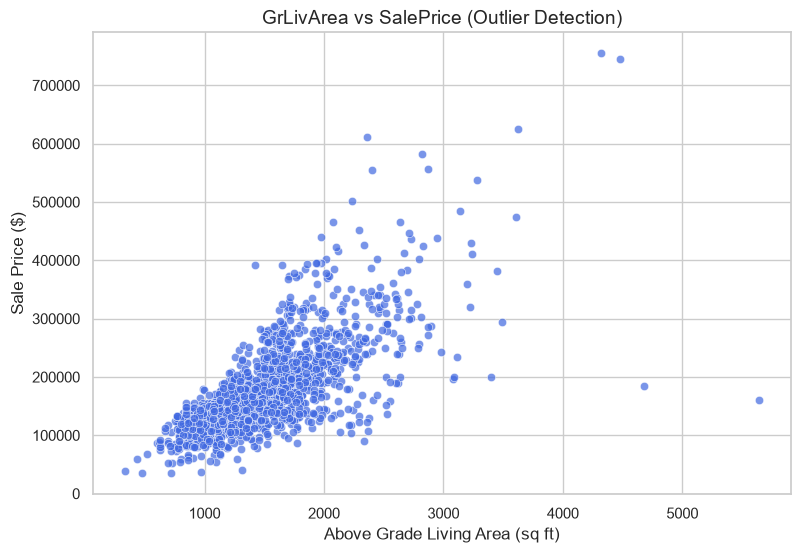

In [23]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df_train, color='royalblue', alpha=0.7)
plt.title('GrLivArea vs SalePrice (Outlier Detection)', fontsize=14)
plt.xlabel('Above Grade Living Area (sq ft)', fontsize=12)
plt.ylabel('Sale Price ($)', fontsize=12)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/grlivarea_vs_saleprice.png', bbox_inches='tight')

plt.show()

#### 4.4 Impact of Overall Quality on Price

**Box Plot of the relationship between Overall Quality and SalePrice**

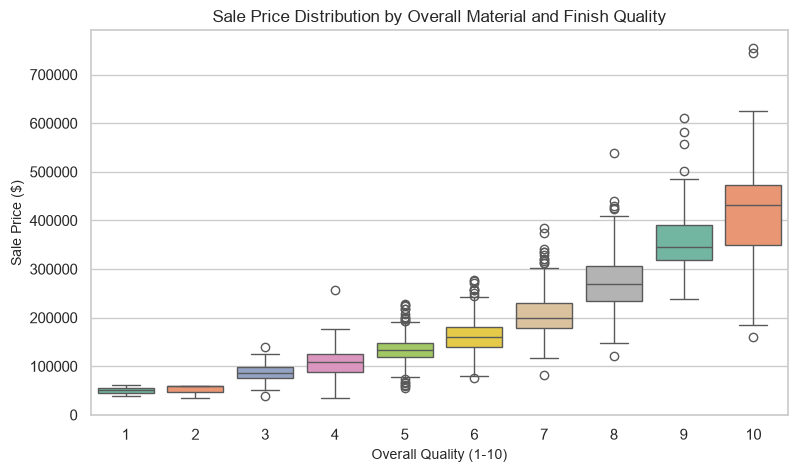

In [50]:
# Analyze the bivariate relationship between Overall Quality and SalePrice 
#Shows the sorted quality levels from 1 to 10
plt.figure(figsize=(9, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df_train, palette='Set2', hue='OverallQual', legend=False)
plt.title('Sale Price Distribution by Overall Material and Finish Quality', fontsize=12)
plt.xlabel('Overall Quality (1-10)', fontsize=10)
plt.ylabel('Sale Price ($)', fontsize=10)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/overall_qual_vs_saleprice.png', bbox_inches='tight')
plt.show()

**Scatterplot between Overall Quality and SalePrice**

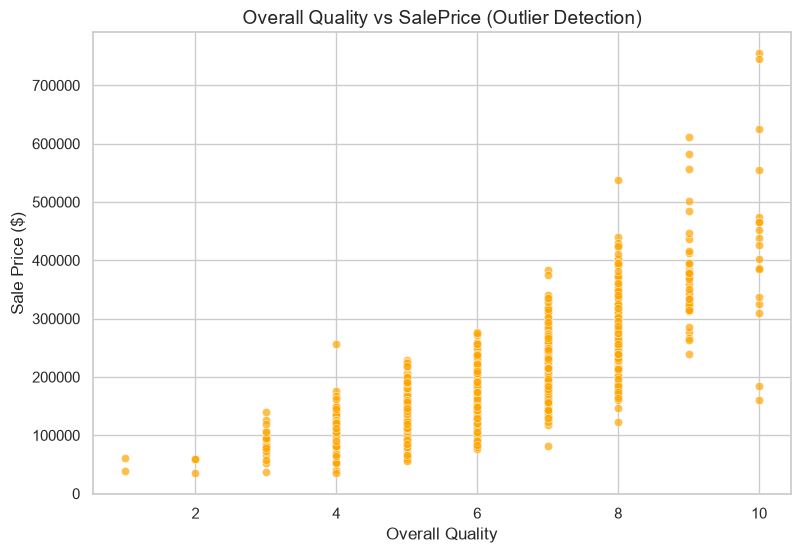

In [75]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x='OverallQual', y='SalePrice', data=df_train, color='orange', alpha=0.7)
plt.title('Overall Quality vs SalePrice (Outlier Detection)', fontsize=14)
plt.xlabel('Overall Quality', fontsize=12)
plt.ylabel('Sale Price ($)', fontsize=12)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/grlivarea_vs_saleprice.png', bbox_inches='tight')

plt.show()

#### 4.4 Relationship between Garage Capacity and Price

**Box plot of Garage Capacity (Cars) and SalePrice**

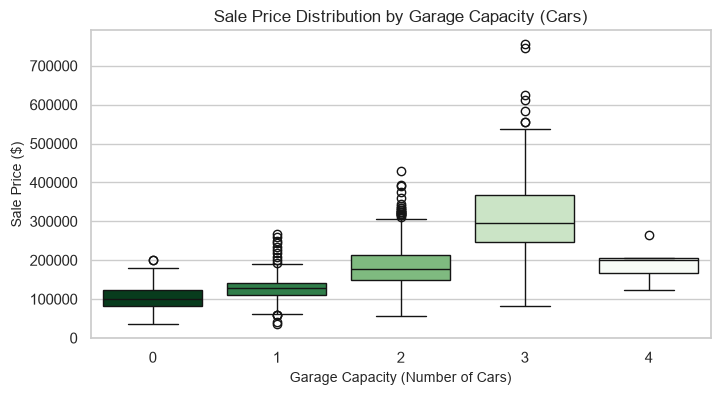

In [79]:
# Analyze the bivariate relationship between Garage Capacity (Cars) and SalePrice using a boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x='GarageCars', y='SalePrice', data=df_train, palette='Greens_r', hue='GarageCars', legend=False)
plt.title('Sale Price Distribution by Garage Capacity (Cars)', fontsize=12)
plt.xlabel('Garage Capacity (Number of Cars)', fontsize=10)
plt.ylabel('Sale Price ($)', fontsize=10)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/garage_cars_vs_saleprice.png', bbox_inches='tight')
plt.show()

#### 4.5 Relationship Between Total Rooms and Price

**Box Plot of the relationship between Total Rooms Above Grade and SalePrice**

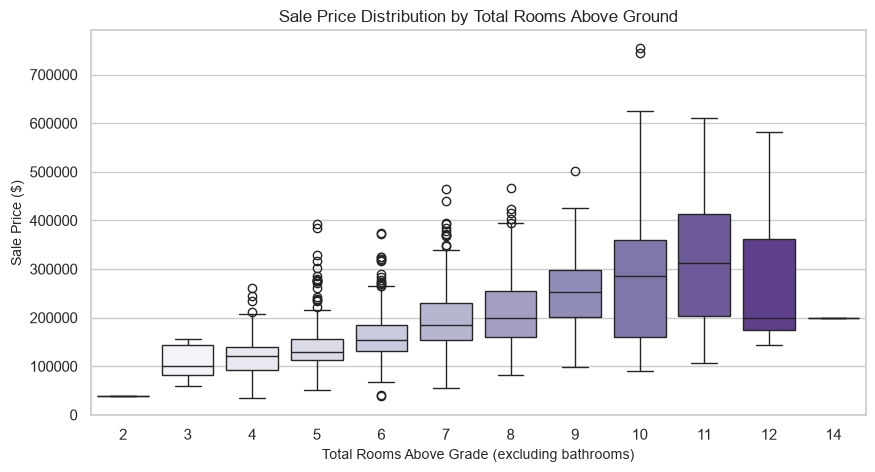

In [53]:
# Analyze the bivariate relationship between Total Rooms Above Grade and SalePrice using a boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(x='TotRmsAbvGrd', y='SalePrice', data=df_train, palette='Purples', hue='TotRmsAbvGrd', legend=False)
plt.title('Sale Price Distribution by Total Rooms Above Ground', fontsize=12)
plt.xlabel('Total Rooms Above Grade (excluding bathrooms)', fontsize=10)
plt.ylabel('Sale Price ($)', fontsize=10)

# Save the plot in the Results folder for the PDF report
plt.savefig('../Results/tot_rms_vs_saleprice.png', bbox_inches='tight')
plt.show()

## 5. Categorical variables Impact ##

#### 5.1 Distribution of Sale Price by Neighborhood

**Boxplot of Sale Price by Neighborhood**

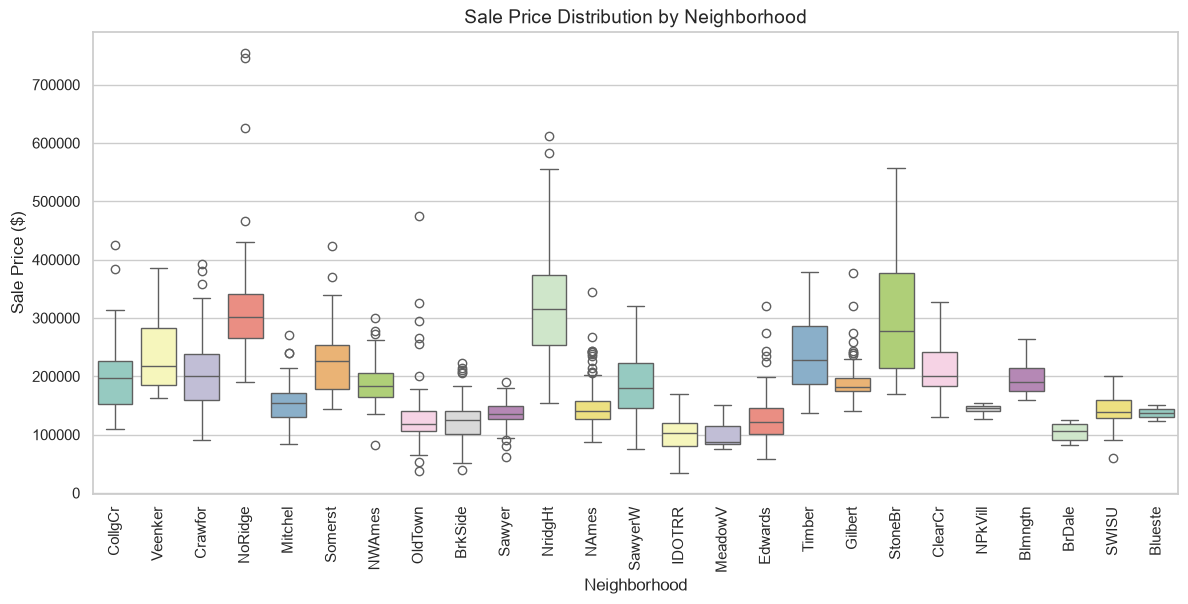

In [46]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='Neighborhood', y='SalePrice', data=df_train, palette='Set3', hue='Neighborhood', legend=False)
plt.xticks(rotation=90) #Rotate the Neighborhood names
plt.title('Sale Price Distribution by Neighborhood', fontsize=14)
plt.xlabel('Neighborhood', fontsize=12)
plt.ylabel('Sale Price ($)', fontsize=12)
plt.savefig('../Results/saleprice_by_neighborhood.png', bbox_inches='tight')

plt.show()